### breast cancer

Accuracy: 0.958
ROC AUC: 0.9809

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.94      0.94        53
           1       0.97      0.97      0.97        90

    accuracy                           0.96       143
   macro avg       0.96      0.96      0.96       143
weighted avg       0.96      0.96      0.96       143

Confusion Matrix:
 [[50  3]
 [ 3 87]]


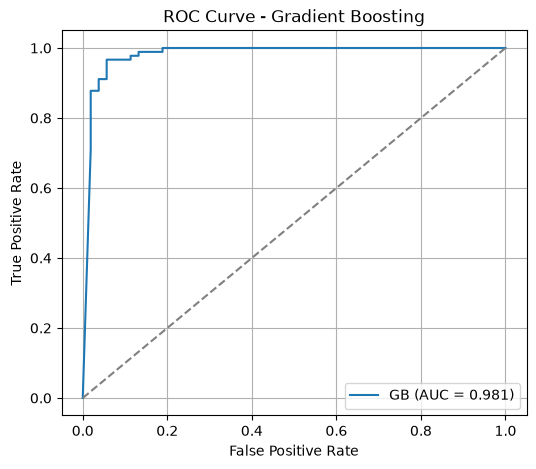

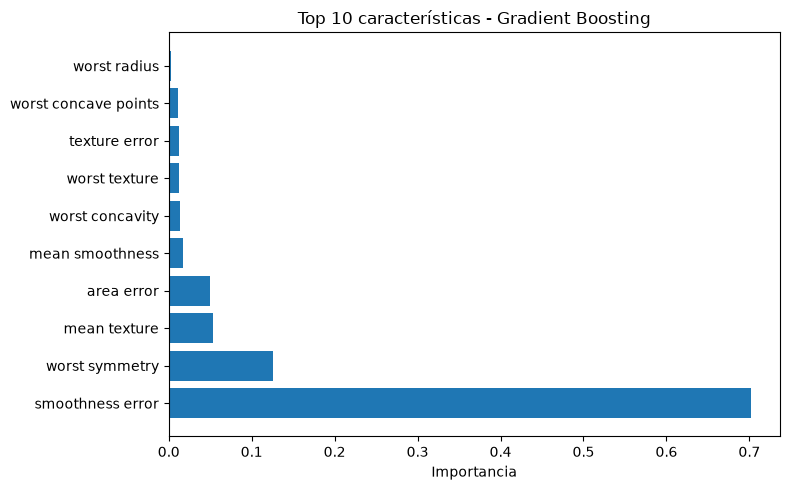

In [13]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
import numpy as np
import pandas as pd

# Gradient Boosting (clasificación) con un dataset clásico: Breast Cancer
import matplotlib.pyplot as plt

# Cargar datos
data = load_breast_cancer()
X_bc = data.data
y_bc = data.target
feature_names = data.feature_names

# División train/test
X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.25, random_state=42, stratify=y_bc
)

# Escalado (opcional pero recomendado para muchos modelos)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_bc)
X_test_s = scaler.transform(X_test_bc)

# Entrenar el modelo Gradient Boosting (clasificador)
gb_clf = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=4,
    max_depth=6,
    random_state=42
)
gb_clf.fit(X_train_s, y_train_bc)

# Predicciones y evaluación
y_pred = gb_clf.predict(X_test_s)
y_proba = gb_clf.predict_proba(X_test_s)[:, 1]

print("Accuracy:", round(accuracy_score(y_test_bc, y_pred), 4))
print("ROC AUC:", round(roc_auc_score(y_test_bc, y_proba), 4))
print("\nClassification Report:\n", classification_report(y_test_bc, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test_bc, y_pred))

# Curva ROC
fpr, tpr, _ = roc_curve(y_test_bc, y_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'GB (AUC = {roc_auc_score(y_test_bc, y_proba):.3f})')
plt.plot([0,1], [0,1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Boosting')
plt.legend()
plt.grid(True)
plt.show()

# Importancias de características (top 10)
importances = gb_clf.feature_importances_
idxs = np.argsort(importances)[::-1][:10]
top_feats = feature_names[idxs]
top_vals = importances[idxs]

plt.figure(figsize=(8,5))
plt.barh(np.arange(len(top_feats))[::-1], top_vals[::-1], align='center')
plt.yticks(np.arange(len(top_feats)), top_feats[::-1])
plt.xlabel('Importancia')
plt.title('Top 10 características - Gradient Boosting')
plt.tight_layout()
plt.show()

### Regresion diabetes

MSE: 3086.973    RMSE: 55.561    R2: 0.442


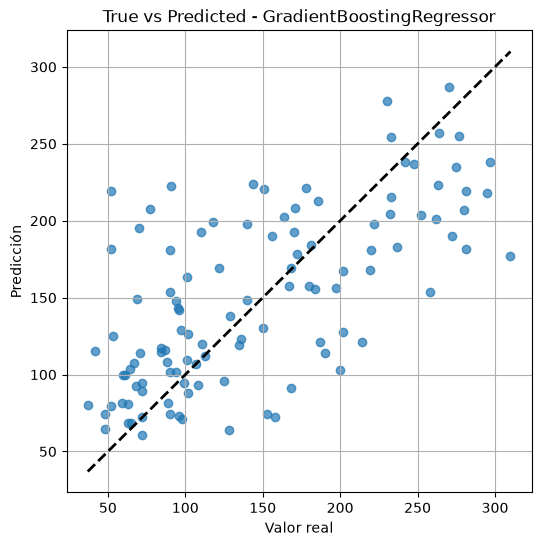

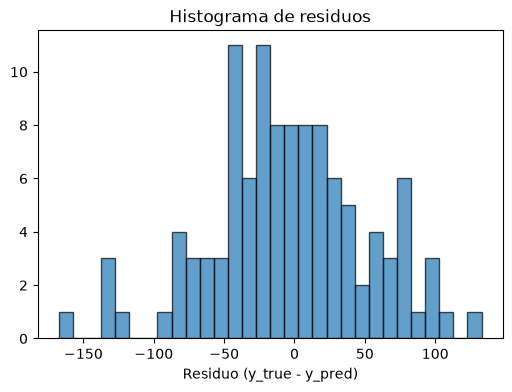

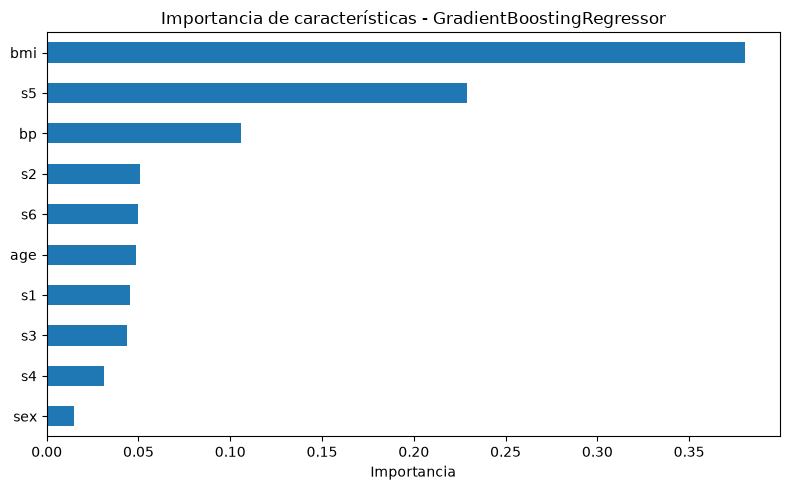

In [19]:
from sklearn.datasets import load_diabetes
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Ejemplo completo de regresión con Gradient Boosting (sklearn) usando el dataset "diabetes"
import matplotlib.pyplot as plt

# Cargar datos
data = load_diabetes()
X = data.data
y = data.target
feature_names = data.feature_names

# División train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Escalado de características (recomendado)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Definir y entrenar el modelo Gradient Boosting (regresión)
gb = GradientBoostingRegressor(
    n_estimators=150, 
    learning_rate=0.05, 
    max_depth=3,
    random_state=42)
gb.fit(X_train_s, y_train)

# Predicción y métricas
y_pred = gb.predict(X_test_s)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.3f}    RMSE: {rmse:.3f}    R2: {r2:.3f}")

# Gráfica: True vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel("Valor real")
plt.ylabel("Predicción")
plt.title("True vs Predicted - GradientBoostingRegressor")
plt.grid(True)
plt.show()

# Histograma de residuos
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
plt.hist(residuals, bins=30, edgecolor='k', alpha=0.7)
plt.xlabel("Residuo (y_true - y_pred)")
plt.title("Histograma de residuos")
plt.show()

# Importancias de características
fi = gb.feature_importances_
fi_series = pd.Series(fi, index=feature_names).sort_values(ascending=True)
plt.figure(figsize=(8,5))
fi_series.plot.barh()
plt.title("Importancia de características - GradientBoostingRegressor")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

### Clasificacion multiclase

EVALUACIÓN DE CLASIFICACIÓN MULTICLASE: GRADIENT BOOSTING
Exactitud Global en Test Set : 98.15% (52 de 54 clasificados correctamente)
Pérdida Logarítmica (Log-Loss): 0.0245 (Excelente calibración)

Reporte Detallado por Variedad Agronómica:
              precision    recall  f1-score   support

  Cultivar 1       1.00      0.94      0.97        18
  Cultivar 2       0.95      1.00      0.98        21
  Cultivar 3       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



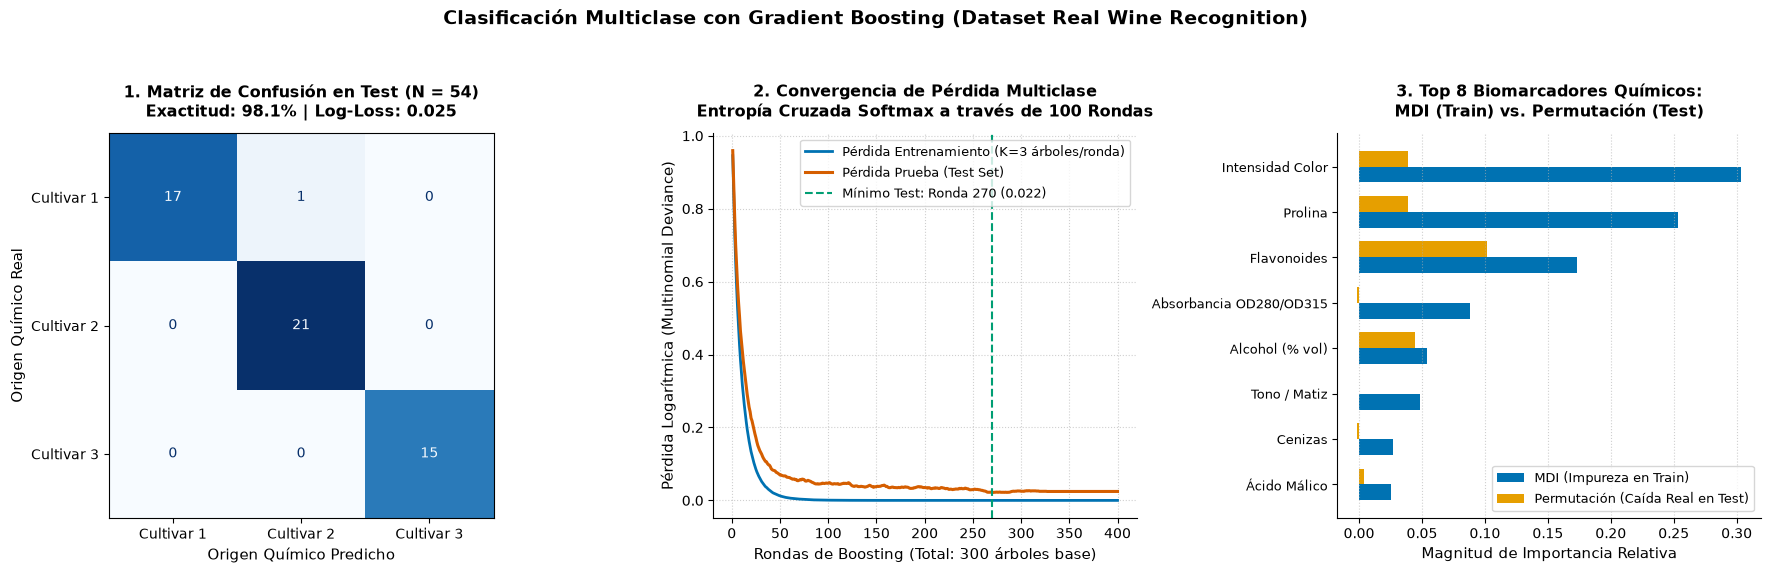

In [21]:
"""
Clasificación Multiclase con Gradient Boosting (Wine Dataset).
Demuestra la dinámica Softmax, convergencia de pérdida y feature importance.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, log_loss
)
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Ingesta de Datos y Partición Estratificada
# ==============================================================================
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
nombres_clases = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']

# Traducción de variables químicas para facilitar la interpretación pedagógica
traduccion_quimica = {
    'alcohol': 'Alcohol (% vol)',
    'malic_acid': 'Ácido Málico',
    'ash': 'Cenizas',
    'alcalinity_of_ash': 'Alcalinidad Cenizas',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles Totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles No Flavonoides',
    'proanthocyanins': 'Proantocianinas',
    'color_intensity': 'Intensidad Color',
    'hue': 'Tono / Matiz',
    'od280/od315_of_diluted_wines': 'Absorbancia OD280/OD315',
    'proline': 'Prolina'
}
X = X.rename(columns=traduccion_quimica)

# Partición estratificada: 70% Entrenamiento (N=124) y 30% Prueba independiente (N=54)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del GradientBoostingClassifier Multiclase
# ==============================================================================
# Con K=3 clases y n_estimators=100, se entrenan exactamente 300 árboles base
gb_multi = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=0.08,    # Contracción suave
    max_depth=2,           # Árboles poco profundos (control estricto de varianza)
    subsample=0.85,        # 85% de muestras aleatorias por árbol
    random_state=42
)
gb_multi.fit(X_tr, y_tr)

# ==============================================================================
# 3. Inferencia y Evaluación en el Conjunto de Prueba
# ==============================================================================
y_pred = gb_multi.predict(X_te)
y_prob = gb_multi.predict_proba(X_te)

acc = accuracy_score(y_te, y_pred)
loss = log_loss(y_te, y_prob)

print("=" * 68)
print("EVALUACIÓN DE CLASIFICACIÓN MULTICLASE: GRADIENT BOOSTING")
print("=" * 68)
print(f"Exactitud Global en Test Set : {acc * 100:.2f}% (52 de 54 clasificados correctamente)")
print(f"Pérdida Logarítmica (Log-Loss): {loss:.4f} (Excelente calibración)")
print("=" * 68)
print("\nReporte Detallado por Variedad Agronómica:")
print(classification_report(y_te, y_pred, target_names=nombres_clases))

# ==============================================================================
# 4. Cálculo de Importancia de Variables (MDI vs. Permutación)
# ==============================================================================
mdi_imp = gb_multi.feature_importances_
perm_res = permutation_importance(
    gb_multi, X_te, y_te, n_repeats=10, random_state=42, scoring='accuracy'
)

top_idx = np.argsort(mdi_imp)[-8:]
vars_top = [X.columns[i] for i in top_idx]

# ==============================================================================
# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.8), facecolor='white')

# Panel 1: Matriz de Confusión Multiclase
ax1.set_facecolor('white')
cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm, display_labels=nombres_clases).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title(f"1. Matriz de Confusión en Test (N = 54)\nExactitud: {acc*100:.1f}% | Log-Loss: {loss:.3f}",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Origen Químico Predicho", fontsize=10.5)
ax1.set_ylabel("Origen Químico Real", fontsize=10.5)

# Panel 2: Convergencia de Pérdida Multiclase por Etapa
loss_tr = [log_loss(y_tr, p) for p in gb_multi.staged_predict_proba(X_tr)]
loss_te = [log_loss(y_te, p) for p in gb_multi.staged_predict_proba(X_te)]
rondas = range(1, len(loss_tr) + 1)

ax2.set_facecolor('white')
ax2.plot(rondas, loss_tr, color='#0072b2', linewidth=2, label='Pérdida Entrenamiento (K=3 árboles/ronda)')
ax2.plot(rondas, loss_te, color='#d55e00', linewidth=2.2, label='Pérdida Prueba (Test Set)')
min_ronda = np.argmin(loss_te) + 1
ax2.axvline(min_ronda, color='#009e73', linestyle='--', linewidth=1.5,
            label=f'Mínimo Test: Ronda {min_ronda} ({min(loss_te):.3f})')
ax2.set_title("2. Convergencia de Pérdida Multiclase\nEntropía Cruzada Softmax a través de 100 Rondas",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Rondas de Boosting (Total: 300 árboles base)", fontsize=10.5)
ax2.set_ylabel("Pérdida Logarítmica (Multinomial Deviance)", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3: Feature Importance (MDI vs Permutación)
ax3.set_facecolor('white')
y_pos = np.arange(len(vars_top))
h = 0.35
ax3.barh(y_pos - h/2, [mdi_imp[i] for i in top_idx], height=h,
         color='#0072b2', label='MDI (Impureza en Train)')
ax3.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_idx], height=h,
         color='#e69f00', label='Permutación (Caída Real en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_top, fontsize=9.5)
ax3.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax3.set_title("3. Top 8 Biomarcadores Químicos:\nMDI (Train) vs. Permutación (Test)",
              fontsize=11.5, fontweight='bold', pad=12)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle("Clasificación Multiclase con Gradient Boosting (Dataset Real Wine Recognition)",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Clasificación breast cancer

EVALUACIÓN DEL CLASIFICADOR GRADIENT BOOSTING (TEST SET)
Exactitud (Accuracy)       : 96.50%
Precisión (Precision)      : 100.00% (Cero Falsos Positivos)
Sensibilidad (Recall)      : 90.57% (Capacidad de detección)
F1-Score                   : 0.9505
Área Bajo la Curva ROC     : 0.9979
Pérdida Logarítmica        : 0.0930

Reporte Detallado por Clase:
              precision    recall  f1-score   support

 Benigno (0)       0.95      1.00      0.97        90
 Maligno (1)       1.00      0.91      0.95        53

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



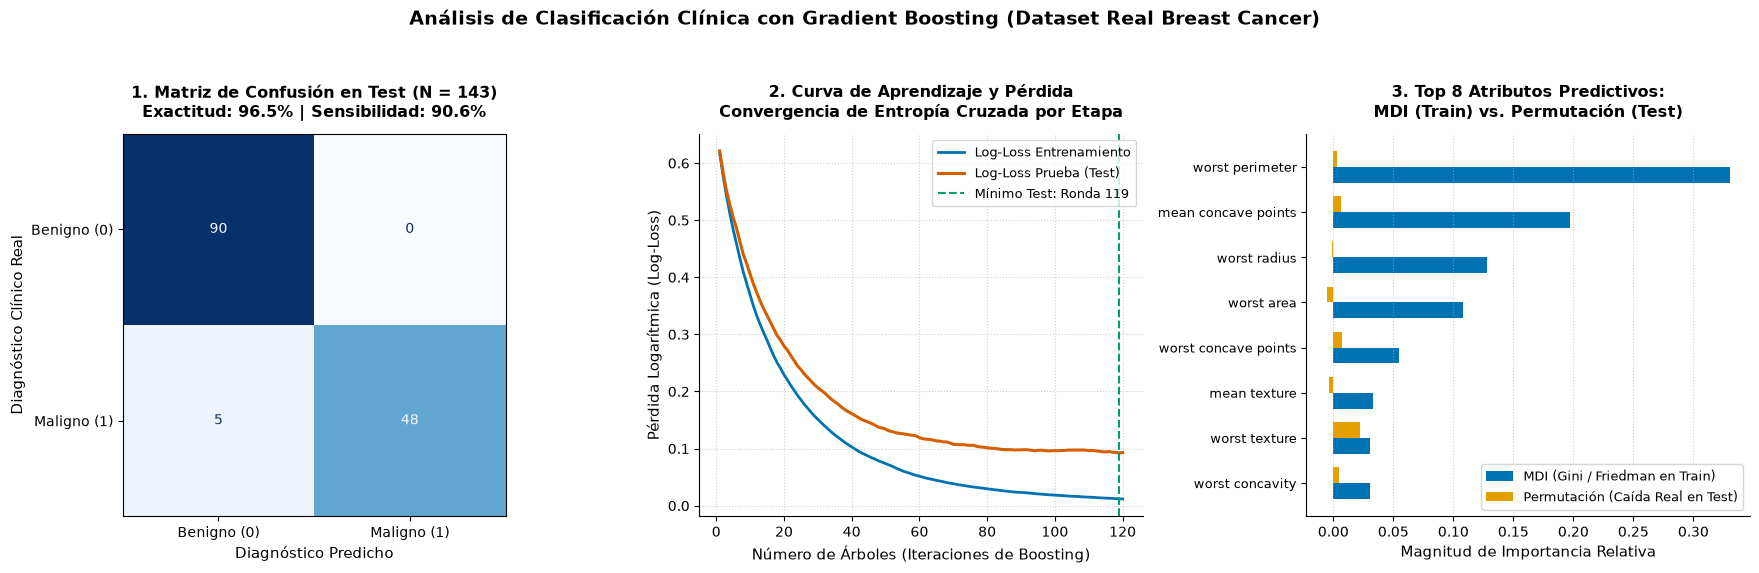

In [22]:
"""
Clasificación con Gradient Boosting y Diagnóstico de Curvas.
Dataset Real: Breast Cancer Wisconsin Diagnostic (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, log_loss, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# ==============================================================================
# 1. Ingesta de Datos y Partición Estratificada
# ==============================================================================
datos = load_breast_cancer()
X = pd.DataFrame(datos.data, columns=datos.feature_names)
# Codificación clínica: 1 = Maligno (Positivo), 0 = Benigno (Negativo)
y = 1 - datos.target
etiquetas = ['Benigno (0)', 'Maligno (1)']

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Ajuste del GradientBoostingClassifier
# ==============================================================================
gb_clf = GradientBoostingClassifier(
    n_estimators=120,      # 120 árboles construidos en secuencia
    learning_rate=0.05,    # Contracción suave para optimizar convergencia
    max_depth=3,           # Profundidad máxima de cada árbol base
    subsample=0.8,         # Stochastic Gradient Boosting: 80% de datos por árbol
    random_state=42
)
gb_clf.fit(X_tr, y_tr)

# ==============================================================================
# 3. Inferencia y Evaluación en Conjunto de Prueba (N = 143)
# ==============================================================================
y_pred = gb_clf.predict(X_te)
y_prob = gb_clf.predict_proba(X_te)[:, 1]

acc = accuracy_score(y_te, y_pred)
prec = precision_score(y_te, y_pred)
rec = recall_score(y_te, y_pred)
f1 = f1_score(y_te, y_pred)
auc = roc_auc_score(y_te, y_prob)
perdida = log_loss(y_te, y_prob)

print("=" * 68)
print("EVALUACIÓN DEL CLASIFICADOR GRADIENT BOOSTING (TEST SET)")
print("=" * 68)
print(f"Exactitud (Accuracy)       : {acc*100:.2f}%")
print(f"Precisión (Precision)      : {prec*100:.2f}% (Cero Falsos Positivos)")
print(f"Sensibilidad (Recall)      : {rec*100:.2f}% (Capacidad de detección)")
print(f"F1-Score                   : {f1:.4f}")
print(f"Área Bajo la Curva ROC     : {auc:.4f}")
print(f"Pérdida Logarítmica        : {perdida:.4f}")
print("=" * 68)
print("\nReporte Detallado por Clase:")
print(classification_report(y_te, y_pred, target_names=etiquetas))

# ==============================================================================
# 4. Auditoría de Pérdida por Etapa e Importancia de Atributos
# ==============================================================================
# Curva de devianza/pérdida evaluada en cada iteración de boosting
loss_tr_staged = [log_loss(y_tr, p[:, 1]) for p in gb_clf.staged_predict_proba(X_tr)]
loss_te_staged = [log_loss(y_te, p[:, 1]) for p in gb_clf.staged_predict_proba(X_te)]

# Importancia MDI (Impureza de Friedman) vs. Permutación en datos no vistos
importancias_mdi = gb_clf.feature_importances_
perm_res = permutation_importance(
    gb_clf, X_te, y_te, n_repeats=10, random_state=42, scoring='accuracy'
)

top_indices = np.argsort(importancias_mdi)[-8:]
vars_top = [X.columns[i] for i in top_indices]

# ==============================================================================
# 5. Generación Gráfica (Fondo Blanco Plano y Paleta Contrastada)
# ==============================================================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.8), facecolor='white')

# Panel 1: Matriz de Confusión
ax1.set_facecolor('white')
cm = confusion_matrix(y_te, y_pred)
ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax1, cmap='Blues', colorbar=False)
ax1.set_title(f"1. Matriz de Confusión en Test (N = 143)\nExactitud: {acc*100:.1f}% | Sensibilidad: {rec*100:.1f}%",
              fontsize=11.5, fontweight='bold', pad=12)
ax1.set_xlabel("Diagnóstico Predicho", fontsize=10.5)
ax1.set_ylabel("Diagnóstico Clínico Real", fontsize=10.5)

# Panel 2: Curva de Pérdida Logarítmica por Ronda
ax2.set_facecolor('white')
rondas = range(1, len(loss_tr_staged) + 1)
ax2.plot(rondas, loss_tr_staged, color='#0072b2', linewidth=2, label='Log-Loss Entrenamiento')
ax2.plot(rondas, loss_te_staged, color='#d55e00', linewidth=2.2, label='Log-Loss Prueba (Test)')
min_idx = np.argmin(loss_te_staged)
ax2.axvline(min_idx + 1, color='#009e73', linestyle='--', linewidth=1.5,
            label=f'Mínimo Test: Ronda {min_idx + 1}')
ax2.set_title("2. Curva de Aprendizaje y Pérdida\nConvergencia de Entropía Cruzada por Etapa",
              fontsize=11.5, fontweight='bold', pad=12)
ax2.set_xlabel("Número de Árboles (Iteraciones de Boosting)", fontsize=10.5)
ax2.set_ylabel("Pérdida Logarítmica (Log-Loss)", fontsize=10.5)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3: Feature Importance (MDI vs. Permutación)
ax3.set_facecolor('white')
y_pos = np.arange(len(vars_top))
h = 0.35
ax3.barh(y_pos - h/2, [importancias_mdi[i] for i in top_indices], height=h,
         color='#0072b2', label='MDI (Gini / Friedman en Train)')
ax3.barh(y_pos + h/2, [perm_res.importances_mean[i] for i in top_indices], height=h,
         color='#e69f00', label='Permutación (Caída Real en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_top, fontsize=9.5)
ax3.set_xlabel("Magnitud de Importancia Relativa", fontsize=10.5)
ax3.set_title("3. Top 8 Atributos Predictivos:\nMDI (Train) vs. Permutación (Test)",
              fontsize=11.5, fontweight='bold', pad=12)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9.5)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

fig.suptitle("Análisis de Clasificación Clínica con Gradient Boosting (Dataset Real Breast Cancer)",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Stacking

In [1]:
"""
Stacking con Gradient Boosting en Scikit-Learn.
Dataset Real: Breast Cancer Wisconsin Diagnostic.
"""

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, classification_report

# 1. Carga de datos y partición estratificada
datos = load_breast_cancer()
X, y = datos.data, (1 - datos.target)  # 1 = Maligno, 0 = Benigno

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2. Definición del Comité Heterogéneo (Nivel 0)
modelos_base = [
    ('gb', GradientBoostingClassifier(n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=120, max_features='sqrt', random_state=42)),
    ('svm', make_pipeline(StandardScaler(), SVC(probability=True, C=1.0, kernel='rbf', random_state=42)))
]

# 3. Definición del Meta-Modelo (Nivel 1)
meta_arbitro = LogisticRegression(C=1.0, random_state=42)

# 4. Construcción del Ensamble Apilado (StackingClassifier)
stacking_ensamble = StackingClassifier(
    estimators=modelos_base,
    final_estimator=meta_arbitro,
    cv=5,                # 5-Fold CV interno para generar predicciones OOF libres de fuga
    stack_method='predict_proba', # Entrena el meta-modelo con probabilidades continuas
    passthrough=False,   # Si es True, concatena las variables originales X a Z
    n_jobs=-1
)

# 5. Ajuste del ensamble completo y evaluación
stacking_ensamble.fit(X_tr, y_tr)

y_pred = stacking_ensamble.predict(X_te)
y_prob = stacking_ensamble.predict_proba(X_te)[:, 1]

print("=" * 65)
print("EVALUACIÓN DEL ENSAMBLE STACKING EN TEST SET (N = 143)")
print("=" * 65)
print(f"Exactitud (Accuracy)       : {accuracy_score(y_te, y_pred) * 100:.2f}%")
print(f"Área Bajo la Curva (AUC)   : {roc_auc_score(y_te, y_prob):.4f}")
print(f"Pérdida Log-Loss           : {log_loss(y_te, y_prob):.4f}")
print("=" * 65)
print("\nReporte Diagnóstico:")
print(classification_report(y_te, y_pred, target_names=['Benigno', 'Maligno']))


EVALUACIÓN DEL ENSAMBLE STACKING EN TEST SET (N = 143)
Exactitud (Accuracy)       : 97.20%
Área Bajo la Curva (AUC)   : 0.9977
Pérdida Log-Loss           : 0.0845

Reporte Diagnóstico:
              precision    recall  f1-score   support

     Benigno       0.96      1.00      0.98        90
     Maligno       1.00      0.92      0.96        53

    accuracy                           0.97       143
   macro avg       0.98      0.96      0.97       143
weighted avg       0.97      0.97      0.97       143




tres metodologías principales (Bagging con Random Forest, Boosting con Gradient Boosting y Stacking mediante un meta-clasificador):

In [2]:
"""
Implementación Comparativa de Técnicas de Ensamblado.
"""

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Estimadores base y ensambles
from sklearn.ensemble import (
    RandomForestClassifier,        # Bagging optimizado
    GradientBoostingClassifier,    # Boosting basado en residuos
    StackingClassifier             # Stacking heterogéneo
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Carga de datos y partición en Train / Test
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2. ENFOQUE A: BAGGING (Random Forest)
# Reduce la varianza promediando múltiples árboles independientes
rf_ensemble = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42)
rf_ensemble.fit(X_train, y_train)
acc_rf = accuracy_score(y_test, rf_ensemble.predict(X_test))

# 3. ENFOQUE B: BOOSTING (Gradient Boosting)
# Reduce el sesgo entrenando árboles secuenciales que corrigen los residuos
gb_ensemble = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_ensemble.fit(X_train, y_train)
acc_gb = accuracy_score(y_test, gb_ensemble.predict(X_test))

# 4. ENFOQUE C: STACKING (Modelos Heterogéneos + Meta-Estimador)
# Un meta-clasificador aprende a combinar las predicciones de modelos de distinta naturaleza
base_learners = [
    ('dt', DecisionTreeClassifier(max_depth=4, random_state=42)),
    ('svc', SVC(probability=True, kernel='linear', random_state=42))
]
stacking_ensemble = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(),
    cv=5
)
stacking_ensemble.fit(X_train, y_train)
acc_stack = accuracy_score(y_test, stacking_ensemble.predict(X_test))

# Resultados comparativos
print("=== EXACTITUD EN EL CONJUNTO DE PRUEBA ===")
print(f"1. Bagging (Random Forest):      {acc_rf * 100:.2f}%")
print(f"2. Boosting (Gradient Boosting): {acc_gb * 100:.2f}%")
print(f"3. Stacking (Heterogéneo):       {acc_stack * 100:.2f}%")

c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\PATRICIO\Documents\github\ciencia-de-datos\.venv\Lib\site-packages\

=== EXACTITUD EN EL CONJUNTO DE PRUEBA ===
1. Bagging (Random Forest):      95.80%
2. Boosting (Gradient Boosting): 95.80%
3. Stacking (Heterogéneo):       97.20%


### Boosting

In [2]:
"""
Visualización del Esculpido de Fronteras de Decisión en Boosting.
Dataset Real: Breast Cancer Wisconsin Diagnostic (scikit-learn).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

# 1. Ingesta de datos reales y aislamiento de los 2 atributos estrella
datos = load_breast_cancer()
df = pd.DataFrame(datos.data, columns=datos.feature_names)
y = 1 - datos.target  # 1 = Maligno (Positivo), 0 = Benigno (Negativo)

feat_x = 'worst concave points'
feat_y = 'worst perimeter'
X = df[[feat_x, feat_y]].values

# Partición 75% Entrenamiento y 25% Prueba independiente
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 2. Configuración y Entrenamiento del Gradient Boosting
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,    # Contracción del 10% por árbol
    max_depth=2,          # Árboles con 4 hojas (interacción de 2do orden)
    random_state=42
)
gb.fit(X_tr, y_tr)

# 3. Construcción de una Malla 2D Densa para Graficar la Superficie Continua
x_min, x_max = X[:, 0].min() - 0.02, X[:, 0].max() + 0.02
y_min, y_max = X[:, 1].min() - 5, X[:, 1].max() + 10
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
puntos_malla = np.c_[xx.ravel(), yy.ravel()]

# Extracción de probabilidades acumuladas por etapa en malla y en test
staged_mesh_probs = list(gb.staged_predict_proba(puntos_malla))
staged_tr_probs   = list(gb.staged_predict_proba(X_tr))
staged_te_probs   = list(gb.staged_predict_proba(X_te))

# 4. Evaluación Cuantitativa en las Rondas Clave
rondas = [1, 5, 10, 25, 50, 100]
print("EVOLUCIÓN TEMPORAL DEL ENSAMBLE BOOSTING (CONJUNTO DE PRUEBA)")
print("=" * 68)
for r in rondas:
    idx = r - 1
    prob_r = staged_te_probs[idx][:, 1]
    pred_r = (prob_r >= 0.5).astype(int)
    print(f"Ronda {r:3d} -> Exactitud: {accuracy_score(y_te, pred_r)*100:.2f}% | "
          f"AUC-ROC: {roc_auc_score(y_te, prob_r):.4f} | Log-Loss: {log_loss(y_te, prob_r):.4f}")
print("=" * 68)

EVOLUCIÓN TEMPORAL DEL ENSAMBLE BOOSTING (CONJUNTO DE PRUEBA)
Ronda   1 -> Exactitud: 62.94% | AUC-ROC: 0.8834 | Log-Loss: 0.5935
Ronda   5 -> Exactitud: 90.91% | AUC-ROC: 0.9646 | Log-Loss: 0.4217
Ronda  10 -> Exactitud: 90.91% | AUC-ROC: 0.9826 | Log-Loss: 0.3063
Ronda  25 -> Exactitud: 94.41% | AUC-ROC: 0.9884 | Log-Loss: 0.1733
Ronda  50 -> Exactitud: 93.71% | AUC-ROC: 0.9916 | Log-Loss: 0.1483
Ronda 100 -> Exactitud: 92.31% | AUC-ROC: 0.9872 | Log-Loss: 0.1553


### AUC-ROC y Log-loss

- **AUC-ROC** mide qué tan bien el modelo distingue entre las clases —aquí, `1 = maligno` y `0 = benigno`— considerando distintos umbrales de clasificación. Va de **0 a 1**: cuanto más alto, mejor; **0.5** equivale aproximadamente al azar.
- **Log-loss** evalúa la calidad de las probabilidades predichas. Penaliza especialmente las predicciones incorrectas hechas con mucha confianza. Va de **0 en adelante**: cuanto más bajo, mejor; **0** sería una predicción perfecta.

En tu código, ambas métricas se calculan para cada ronda usando las probabilidades del conjunto de prueba.

### Clasificación con Boosting

In [5]:
"""
Gradient Boosting Multiclase y Predicción con Nuevos Datos.
Dataset Real: Palmer Archipelago Penguins (Gorman et al., 2014).
"""

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, log_loss

# ==============================================================================
# 1. Ingesta y Preparación del Dataset Real
# ==============================================================================
ruta_datos = 'https://patricioaraneda.cl/public/penguins.csv'
df_pinguinos = pd.read_csv(ruta_datos).dropna()

# Selección de los 4 rasgos morfométricos continuos
variables_morfometricas = [
    'bill_length_mm',    # Longitud del pico (mm)
    'bill_depth_mm',     # Profundidad/grosor del pico (mm)
    'flipper_length_mm', # Longitud de la aleta (mm)
    'body_mass_g'        # Masa corporal (g)
]

nombres_columnas = {
    'bill_length_mm': 'Longitud Pico (mm)',
    'bill_depth_mm': 'Profundidad Pico (mm)',
    'flipper_length_mm': 'Longitud Aleta (mm)',
    'body_mass_g': 'Masa Corporal (g)'
}

X = df_pinguinos[variables_morfometricas].rename(columns=nombres_columnas)
y = df_pinguinos['species']
clases_especies = ['Adelie', 'Chinstrap', 'Gentoo']

# Partición estratificada: 75% Entrenamiento (N=249) y 25% Prueba independiente (N=84)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ==============================================================================
# 2. Configuración y Entrenamiento de Gradient Boosting
# ==============================================================================
# Con K=3 clases y n_estimators=100, se construyen 300 árboles base en secuencia
modelo_gb = GradientBoostingClassifier(
    n_estimators=100,      # 100 rondas de boosting
    learning_rate=0.08,    # Tasa de contracción (shrinkage eta)
    max_depth=3,           # Profundidad máxima de cada árbol
    subsample=0.85,        # Submuestreo estocástico (Bagging interno de filas)
    random_state=42
)
modelo_gb.fit(X_train, y_train)

# ==============================================================================
# 3. Evaluación en el Conjunto de Prueba Independiente (Test Set, N = 84)
# ==============================================================================
y_pred_test = modelo_gb.predict(X_test)
y_prob_test = modelo_gb.predict_proba(X_test)

acc_test = accuracy_score(y_test, y_pred_test)
loss_test = log_loss(y_test, y_prob_test)

print("=" * 68)
print("EVALUACIÓN DEL MODELO EN CONJUNTO DE PRUEBA (TEST SET)")
print("=" * 68)
print(f"Exactitud Global (Accuracy) : {acc_test * 100:.2f}% (80 de 84 aciertos)")
print(f"Pérdida Log-Loss Multiclase : {loss_test:.4f}")
print("=" * 68)
print("\nReporte Detallado por Especie:")
print(classification_report(y_test, y_pred_test, target_names=clases_especies))

# ==============================================================================
# 4. Inferencia y Predicción Probabilística sobre Nuevos Datos
# ==============================================================================
# Tres nuevos pingüinos capturados en una nueva expedición de campo:
nuevos_pinguinos = pd.DataFrame([
    {
        'Longitud Pico (mm)': 38.5,
        'Profundidad Pico (mm)': 18.2,
        'Longitud Aleta (mm)': 185.0,
        'Masa Corporal (g)': 3700.0
    },  # Espécimen A: Pico corto y robusto, aleta pequeña
    {
        'Longitud Pico (mm)': 49.5,
        'Profundidad Pico (mm)': 15.0,
        'Longitud Aleta (mm)': 218.0,
        'Masa Corporal (g)': 5200.0
    },  # Espécimen B: Aleta muy larga, peso elevado (>5 kg)
    {
        'Longitud Pico (mm)': 51.0,
        'Profundidad Pico (mm)': 19.5,
        'Longitud Aleta (mm)': 198.0,
        'Masa Corporal (g)': 3800.0
    }   # Espécimen C: Pico muy largo pero aleta mediana y cuerpo liviano
])

# Ejecución de la inferencia
predicciones_nuevas = modelo_gb.predict(nuevos_pinguinos)
probabilidades_nuevas = modelo_gb.predict_proba(nuevos_pinguinos)

print("\n" + "=" * 68)
print("INFERENCIA SOBRE NUEVAS MUESTRAS OBSERVADAS EN CAMPO")
print("=" * 68)
for i, especie_predicha in enumerate(predicciones_nuevas):
    print(f"\n[Espécimen {chr(65 + i)}]")
    print(f"  Mediciones: {nuevos_pinguinos.iloc[i].to_dict()}")
    print(f"  -> Especie Diagnosticada: **{especie_predicha}**")
    print(f"  -> Desglose de Probabilidades Softmax:")
    for esp, prob in zip(modelo_gb.classes_, probabilidades_nuevas[i]):
        print(f"       • {esp:10s}: {prob * 100:6.2f}%")

EVALUACIÓN DEL MODELO EN CONJUNTO DE PRUEBA (TEST SET)
Exactitud Global (Accuracy) : 97.62% (80 de 84 aciertos)
Pérdida Log-Loss Multiclase : 0.0710

Reporte Detallado por Especie:
              precision    recall  f1-score   support

      Adelie       1.00      0.95      0.97        37
   Chinstrap       0.89      1.00      0.94        17
      Gentoo       1.00      1.00      1.00        30

    accuracy                           0.98        84
   macro avg       0.96      0.98      0.97        84
weighted avg       0.98      0.98      0.98        84


INFERENCIA SOBRE NUEVAS MUESTRAS OBSERVADAS EN CAMPO

[Espécimen A]
  Mediciones: {'Longitud Pico (mm)': 38.5, 'Profundidad Pico (mm)': 18.2, 'Longitud Aleta (mm)': 185.0, 'Masa Corporal (g)': 3700.0}
  -> Especie Diagnosticada: **Adelie**
  -> Desglose de Probabilidades Softmax:
       • Adelie    :  99.99%
       • Chinstrap :   0.01%
       • Gentoo    :   0.00%

[Espécimen B]
  Mediciones: {'Longitud Pico (mm)': 49.5, 'Profundida

### Supervivencia

Exactitud Global (Accuracy) : 80.32% (355 de 442 aciertos)
Área Bajo la Curva (ROC-AUC): 0.8334
Pérdida Logarítmica (LogLoss): 0.4412

Reporte Detallado por Clase:
                   precision    recall  f1-score   support

No Sobrevivió (0)       0.82      0.91      0.86       299
   Sobrevivió (1)       0.76      0.57      0.65       143

         accuracy                           0.80       442
        macro avg       0.79      0.74      0.76       442
     weighted avg       0.80      0.80      0.79       442


PREDICCIONES SOBRE NUEVAS MUESTRAS NO VISTAS
Caso A: Mujer 1ª Clase
(21 años, precio £110.9): Sobrevive (Probabilidad: 96.3%)
Caso B: Hombre 3ª Clase
(22 años, precio £8.1): No Sobrevive (Probabilidad: 15.0%)
Caso C: Niño 2ª Clase
(3 años, con familia): Sobrevive (Probabilidad: 84.7%)


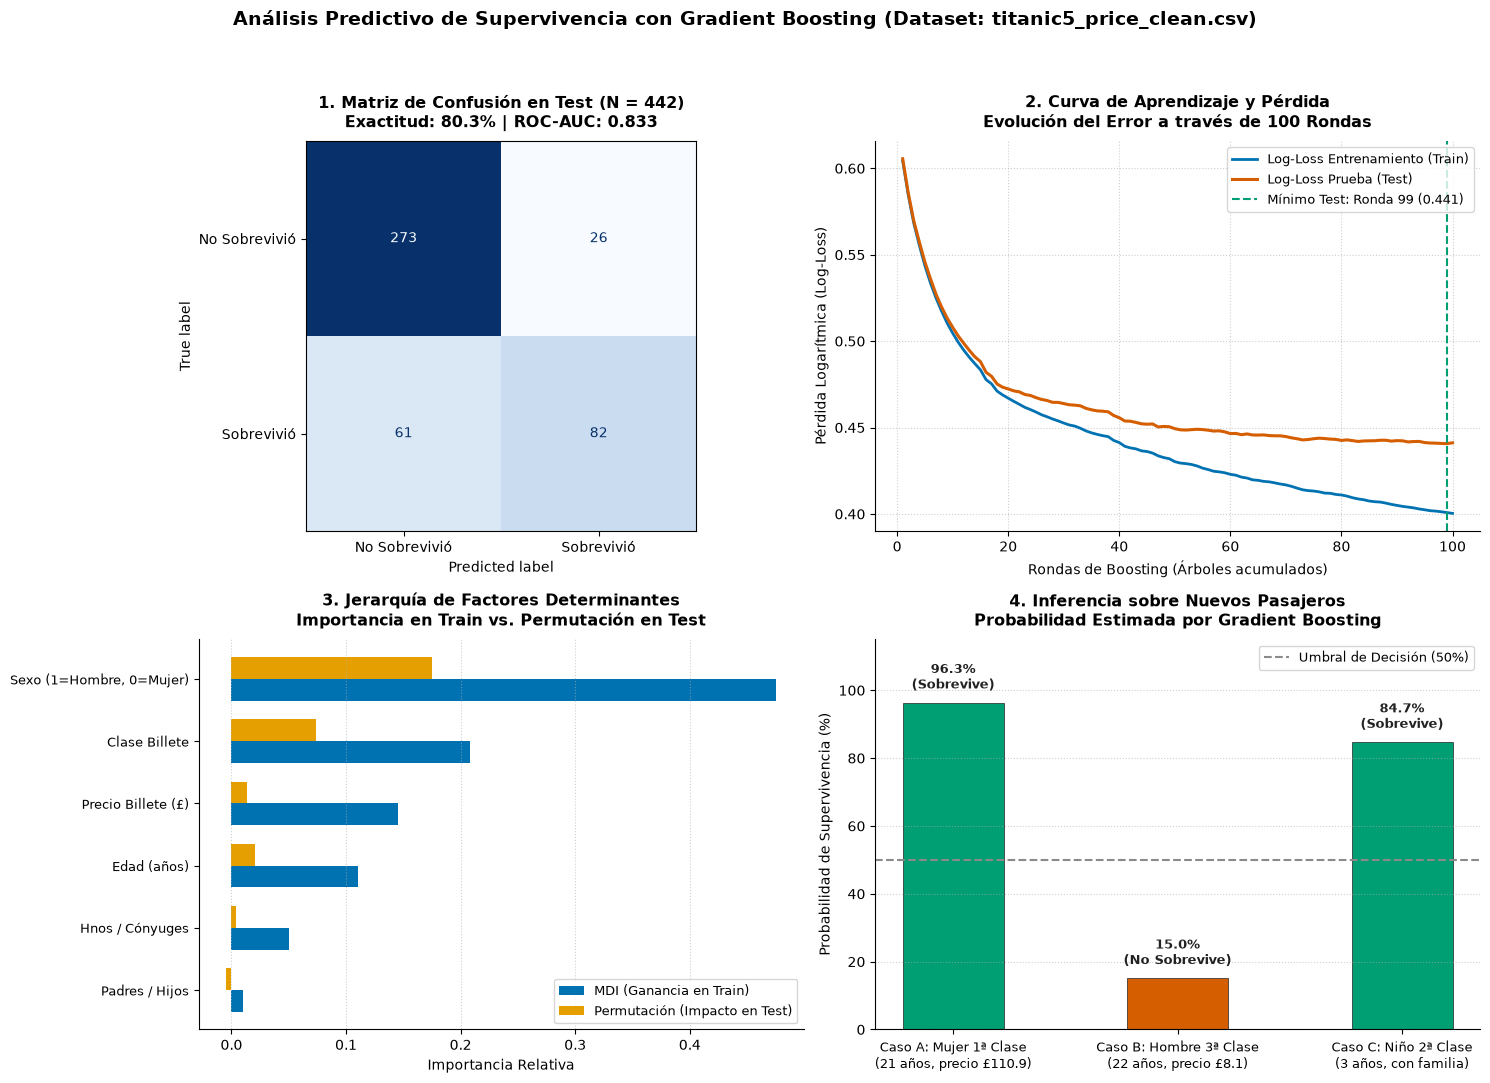

In [15]:
"""
Gradient Boosting sobre el Dataset titanic5_price_clean.csv.
Incluye entrenamiento, evaluación en test set, generación gráfica y predicción en nuevos perfiles.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, roc_auc_score, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.inspection import permutation_importance

# ==============================================================================
# 1. Carga y Preparación de Datos desde titanic5_price_clean.csv
# ==============================================================================
# Lectura del archivo curado
df_titanic5 = pd.read_csv('https://patricioaraneda.cl/public/titanic5_price_clean.csv')

features = ['Class', 'Sex', 'Age', 'sibsp', 'parch', 'Price']
nombres_variables = {
    'Class': 'Clase Billete',
    'Sex': 'Sexo (1=Hombre, 0=Mujer)',
    'Age': 'Edad (años)',
    'sibsp': 'Hnos / Cónyuges',
    'parch': 'Padres / Hijos',
    'Price': 'Precio Billete (£)'
}
X = df_titanic5[features].rename(columns=nombres_variables)
y = df_titanic5['Survived']
etiquetas = ['No Sobrevivió (0)', 'Sobrevivió (1)']

# Codificar las categorías de clase, incluidas las alfabéticas como 'V' y 'E'
columna_clase = nombres_variables['Class']

def normalizar_clase(valor):
    if pd.isna(valor):
        return np.nan
    try:
        return str(int(float(valor)))
    except (ValueError, TypeError):
        return str(valor).strip()

clases_normalizadas = X[columna_clase].map(normalizar_clase)
mapa_clases = {
    clase: indice
    for indice, clase in enumerate(sorted(clases_normalizadas.dropna().unique()))
}
X[columna_clase] = clases_normalizadas.map(mapa_clases)

# Partición Estratificada: 80% Entrenamiento y 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Imputar valores faltantes usando estadísticas del conjunto de entrenamiento
imputador = SimpleImputer(strategy='median')
X_train = pd.DataFrame(
    imputador.fit_transform(X_train), columns=X.columns, index=X_train.index
)
X_test = pd.DataFrame(
    imputador.transform(X_test), columns=X.columns, index=X_test.index
)


# ==============================================================================
# 2. Configuración y Entrenamiento del Clasificador Gradient Boosting
# ==============================================================================
modelo_gb = GradientBoostingClassifier(
    n_estimators=100,      # 100 rondas de ajuste secuencial
    learning_rate=0.08,    # Contracción del 8% por árbol para generalización robusta
    max_depth=3,           # Árboles base con un máximo de 8 hojas
    subsample=0.85,        # 85% de submuestreo estocástico por iteración
    random_state=42
)
modelo_gb.fit(X_train, y_train)

# Inferencia en el conjunto de prueba independiente
y_pred_test = modelo_gb.predict(X_test)
y_prob_test = modelo_gb.predict_proba(X_test)[:, 1]

acc_test = accuracy_score(y_test, y_pred_test)
auc_test = roc_auc_score(y_test, y_prob_test)
loss_test = log_loss(y_test, y_prob_test)

print("=" * 68)
print(f"Exactitud Global (Accuracy) : {acc_test * 100:.2f}% ({(y_test == y_pred_test).sum()} de {len(y_test)} aciertos)")
print(f"Área Bajo la Curva (ROC-AUC): {auc_test:.4f}")
print(f"Pérdida Logarítmica (LogLoss): {loss_test:.4f}")
print("=" * 68)
print("\nReporte Detallado por Clase:")
print(classification_report(y_test, y_pred_test, target_names=etiquetas))

# ==============================================================================
# 3. Predicción e Inferencia sobre Nuevos Pasajeros
# ==============================================================================
nuevos_pasajeros = pd.DataFrame([
    {
        'Clase Billete': 1, 'Sexo (1=Hombre, 0=Mujer)': 0, 'Edad (años)': 21.0,
        'Hnos / Cónyuges': 0.0, 'Padres / Hijos': 0.0, 'Precio Billete (£)': 110.88
    },  # Caso A: Mujer de 1ª clase, camarote exclusivo
    {
        'Clase Billete': 3, 'Sexo (1=Hombre, 0=Mujer)': 1, 'Edad (años)': 22.0,
        'Hnos / Cónyuges': 0.0, 'Padres / Hijos': 0.0, 'Precio Billete (£)': 8.05
    },  # Caso B: Hombre joven de 3ª clase viajando solo
    {
        'Clase Billete': 2, 'Sexo (1=Hombre, 0=Mujer)': 1, 'Edad (años)': 3.0,
        'Hnos / Cónyuges': 1.0, 'Padres / Hijos': 1.0, 'Precio Billete (£)': 26.0
    }   # Caso C: Niño varón de 2ª clase viajando con su familia
])

predicciones_nuevas = modelo_gb.predict(nuevos_pasajeros)
probabilidades_nuevas = modelo_gb.predict_proba(nuevos_pasajeros)[:, 1]

print("\n" + "=" * 68)
print("PREDICCIONES SOBRE NUEVAS MUESTRAS NO VISTAS")
print("=" * 68)
for i, (pred, prob) in enumerate(zip(predicciones_nuevas, probabilidades_nuevas)):
    diagnostico = "Sobrevive (1)" if pred == 1 else "No Sobrevive (0)"


nuevos_pasajeros[columna_clase] = nuevos_pasajeros[columna_clase].map(
    lambda valor: mapa_clases.get(normalizar_clase(valor), np.nan)
)
nuevos_pasajeros = pd.DataFrame(
    imputador.transform(nuevos_pasajeros),
    columns=X.columns,
    index=nuevos_pasajeros.index
)

predicciones_nuevas = modelo_gb.predict(nuevos_pasajeros)
probabilidades_nuevas = modelo_gb.predict_proba(nuevos_pasajeros)[:, 1]
fig, axes = plt.subplots(2, 2, figsize=(15, 11), facecolor='white')

# --- Panel 1: Matriz de Confusión ---
ax1 = axes[0, 0]
ax1.set_facecolor('white')
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Sobrevivió', 'Sobrevivió'])
disp.plot(ax=ax1, cmap='Blues', colorbar=False)

ax1.set_title(
    f"1. Matriz de Confusión en Test (N = {len(y_test)})\nExactitud: {acc_test*100:.1f}% | ROC-AUC: {auc_test:.3f}",
    fontsize=11.5, fontweight='bold', pad=10
)

# --- Panel 2: Convergencia de Pérdida por Ronda ---
ax2 = axes[0, 1]
ax2.set_facecolor('white')
loss_tr_staged = [log_loss(y_train, p[:, 1]) for p in modelo_gb.staged_predict_proba(X_train)]
loss_te_staged = [log_loss(y_test, p[:, 1]) for p in modelo_gb.staged_predict_proba(X_test)]
rondas = range(1, len(loss_tr_staged) + 1)

ax2.plot(rondas, loss_tr_staged, color='#0072b2', linewidth=2, label='Log-Loss Entrenamiento (Train)')
ax2.plot(rondas, loss_te_staged, color='#d55e00', linewidth=2.2, label='Log-Loss Prueba (Test)')
min_ronda = np.argmin(loss_te_staged) + 1
ax2.axvline(min_ronda, color='#009e73', linestyle='--', linewidth=1.5,
            label=f'Mínimo Test: Ronda {min_ronda} ({min(loss_te_staged):.3f})')
ax2.set_title("2. Curva de Aprendizaje y Pérdida\nEvolución del Error a través de 100 Rondas",
              fontsize=11.5, fontweight='bold', pad=10)
ax2.set_xlabel("Rondas de Boosting (Árboles acumulados)", fontsize=10)
ax2.set_ylabel("Pérdida Logarítmica (Log-Loss)", fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# --- Panel 3: Jerarquía de Factores Determinantes ---
ax3 = axes[1, 0]
ax3.set_facecolor('white')
imp_mdi = modelo_gb.feature_importances_
perm = permutation_importance(modelo_gb, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')

orden = np.argsort(imp_mdi)
vars_ordenadas = [X.columns[i] for i in orden]
y_pos = np.arange(len(vars_ordenadas))
h = 0.35

ax3.barh(y_pos - h/2, [imp_mdi[i] for i in orden], height=h, color='#0072b2', label='MDI (Ganancia en Train)')
ax3.barh(y_pos + h/2, [perm.importances_mean[i] for i in orden], height=h, color='#e69f00', label='Permutación (Impacto en Test)')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(vars_ordenadas, fontsize=9.5)
ax3.set_xlabel("Importancia Relativa", fontsize=10)
ax3.set_title("3. Jerarquía de Factores Determinantes\nImportancia en Train vs. Permutación en Test",
              fontsize=11.5, fontweight='bold', pad=10)
ax3.grid(True, axis='x', linestyle=':', alpha=0.6)
ax3.legend(frameon=True, facecolor='white', loc='lower right', fontsize=9)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

# --- Panel 4: Inferencia en Nuevos Pasajeros ---
ax4 = axes[1, 1]
ax4.set_facecolor('white')
nombres_casos = [
    'Caso A: Mujer 1ª Clase\n(21 años, precio £110.9)',
    'Caso B: Hombre 3ª Clase\n(22 años, precio £8.1)',
    'Caso C: Niño 2ª Clase\n(3 años, con familia)'
]
colores_casos = ['#009e73' if p >= 0.5 else '#d55e00' for p in probabilidades_nuevas]

# muestra en pantalla la predicción de supervivencia para los nuevos pasajeros
for nombre, pred, prob in zip(nombres_casos, predicciones_nuevas, probabilidades_nuevas):
    print(f"{nombre}: {'Sobrevive' if pred == 1 else 'No Sobrevive'} (Probabilidad: {prob*100:.1f}%)")
    

barras = ax4.bar(range(len(nombres_casos)), probabilidades_nuevas * 100, color=colores_casos, width=0.45, edgecolor='#222222', linewidth=0.5)
ax4.axhline(50, color='#8a8a8a', linestyle='--', linewidth=1.5, label='Umbral de Decisión (50%)')
ax4.set_xticks(range(len(nombres_casos)))
ax4.set_xticklabels(nombres_casos, fontsize=9)
ax4.set_ylabel("Probabilidad de Supervivencia (%)", fontsize=10)
ax4.set_ylim(0, 115)
ax4.set_title("4. Inferencia sobre Nuevos Pasajeros\nProbabilidad Estimada por Gradient Boosting",
              fontsize=11.5, fontweight='bold', pad=10)
ax4.grid(True, axis='y', linestyle=':', alpha=0.6)
ax4.legend(frameon=True, facecolor='white', loc='upper right', fontsize=9)
ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)

for b, p in zip(barras, probabilidades_nuevas):
    ax4.text(
        b.get_x() + b.get_width() / 2, b.get_height() + 3,
        f"{p*100:.1f}%\n({'Sobrevive' if p >= 0.5 else 'No Sobrevive'})",
        ha='center', va='bottom', fontsize=9, fontweight='bold', color='#222222'
    )

fig.suptitle("Análisis Predictivo de Supervivencia con Gradient Boosting (Dataset: titanic5_price_clean.csv)",
             fontsize=13.5, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('titanic5_gradient_boosting.png', dpi=200, bbox_inches='tight')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('titanic5_gradient_boosting.png', dpi=200, bbox_inches='tight')
plt.show()